Setup

In [1]:
import sys
sys.path.append("..")   # lets the notebook see the /src folder

import os
os.chdir("..")          # move to project root so data/ paths work

import pandas as pd
import matplotlib.pyplot as plt
from src.data_loader import load_year

YEARS = [2019, 2021, 2023, 2025]

Download and Load

In [2]:
data = {}
for y in YEARS:
    data[y] = load_year(y)

# Basic size of each year
for y, df in data.items():
    print(y, "-> rows:", df.shape[0], " columns:", df.shape[1])

2019: downloading... (may take a minute)
2019: saved to data\raw\survey_2019.csv
2021: downloading... (may take a minute)
2021: saved to data\raw\survey_2021.csv
2023: downloading... (may take a minute)
2023: saved to data\raw\survey_2023.csv
2025: downloading... (may take a minute)
2025: saved to data\raw\survey_2025.csv
2019 -> rows: 88883  columns: 85
2021 -> rows: 83439  columns: 48
2023 -> rows: 89184  columns: 84
2025 -> rows: 49191  columns: 172


Look at one year

In [4]:
# Search for columns that look like salary, language, job role, country
keywords = ["comp", "salary", "language", "devtype", "country", "yearscode", "edlevel"]
for y, df in data.items():
    print(f"\n=== {y} ===")
    for col in df.columns:
        if any(k in col.lower() for k in keywords):
            print("  ", col)


=== 2019 ===
   Country
   EdLevel
   DevType
   YearsCode
   YearsCodePro
   CompTotal
   CompFreq
   ConvertedComp
   LanguageWorkedWith
   LanguageDesireNextYear

=== 2021 ===
   Country
   UK_Country
   EdLevel
   YearsCode
   YearsCodePro
   DevType
   CompTotal
   CompFreq
   LanguageHaveWorkedWith
   LanguageWantToWorkWith
   ConvertedCompYearly

=== 2023 ===
   EdLevel
   YearsCode
   YearsCodePro
   DevType
   Country
   CompTotal
   LanguageHaveWorkedWith
   LanguageWantToWorkWith
   ConvertedCompYearly

=== 2025 ===
   EdLevel
   YearsCode
   DevType
   Country
   CompTotal
   LanguageChoice
   LanguageHaveWorkedWith
   LanguageWantToWorkWith
   LanguageAdmired
   LanguagesHaveEntry
   LanguagesWantEntry
   AIComplex
   ConvertedCompYearly


Missing Values

AIAgentObsWrite         99.463316
SOTagsWant Entry        99.125856
SOTagsHaveEntry         99.068935
AIModelsWantEntry       99.034376
AIAgentOrchWrite        99.028278
JobSatPoints_15_TEXT    98.650160
AIAgentKnowWrite        98.442805
AIModelsHaveEntry       98.422476
SO_Actions_15_TEXT      98.326930
AIAgentExtWrite         98.253746
CommPlatformWantEntr    97.593056
CommPlatformHaveEntr    96.999451
DatabaseWantEntry       96.883576
OfficeStackWantEntry    96.712813
TechOppose_15_TEXT      96.651827
dtype: float64


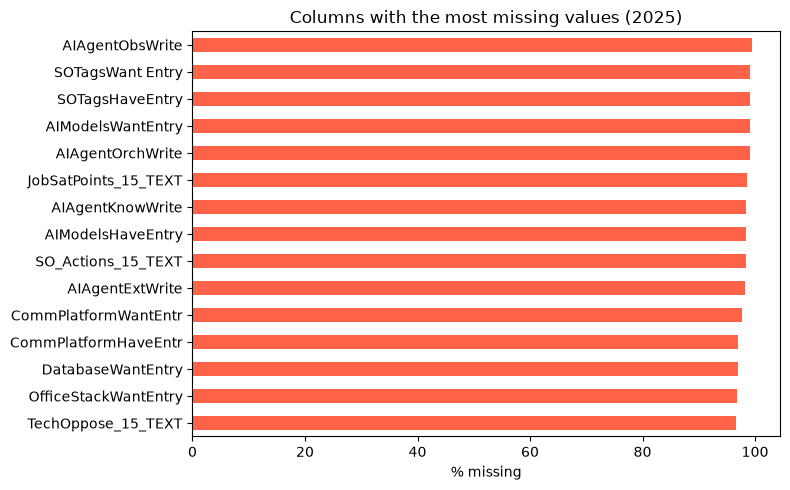

In [5]:
df = data[2025]
missing = (df.isnull().mean() * 100).sort_values(ascending=False)
print(missing.head(15))

# Visual: top 15 columns with most missing data
missing.head(15).plot(kind="barh", figsize=(8, 5), color="tomato")
plt.xlabel("% missing")
plt.title("Columns with the most missing values (2025)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

First trend chart, Language use over the years

In [6]:
def find_language_col(df):
    """Return the 'languages used' column, whichever name this year uses."""
    for name in ["LanguageHaveWorkedWith", "LanguageWorkedWith"]:
        if name in df.columns:
            return name
    return None

def language_share(df, col, lang):
    """% of people who answered that said they use `lang`."""
    answered = df[col].dropna()
    # answers are separated by ';'
    uses = answered.apply(lambda x: lang in x.split(";"))
    return uses.mean() * 100

languages = ["Python", "JavaScript", "TypeScript", "Rust", "Go", "Java"]
rows = []
for y, df in data.items():
    col = find_language_col(df)
    print(y, "-> using column:", col)
    if col is None:
        continue
    for lang in languages:
        rows.append({"year": y, "language": lang,
                     "share_%": language_share(df, col, lang)})

trend = pd.DataFrame(rows)
table = trend.pivot(index="year", columns="language", values="share_%").round(1)
table

2019 -> using column: LanguageWorkedWith
2021 -> using column: LanguageHaveWorkedWith
2023 -> using column: LanguageHaveWorkedWith
2025 -> using column: LanguageHaveWorkedWith


language,Go,Java,JavaScript,Python,Rust,TypeScript
year,,,,,,
2019,8.2,41.0,67.6,41.6,3.2,21.2
2021,9.6,35.4,65.1,48.3,7.0,30.2
2023,13.3,30.7,63.9,49.5,13.1,39.1
2025,16.5,29.5,66.3,58.1,14.9,43.8


Plot it

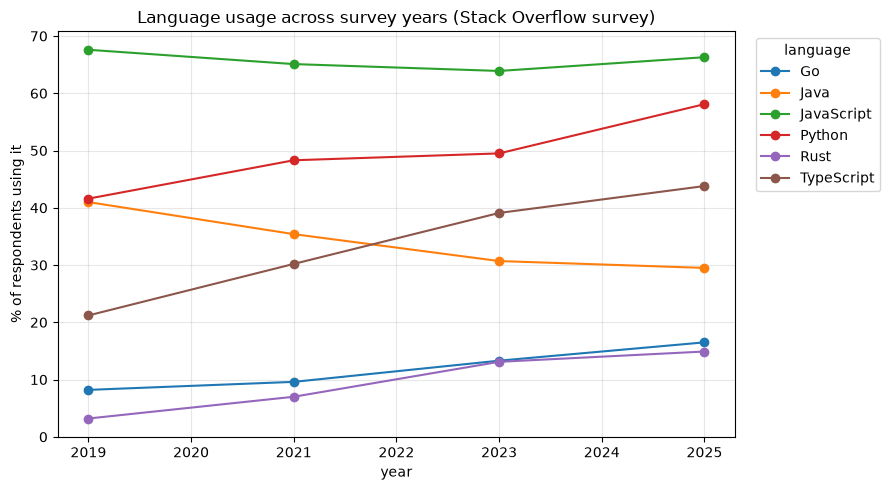

In [8]:
table.plot(marker="o", figsize=(9, 5))
plt.ylabel("% of respondents using it")
plt.title("Language usage across survey years (Stack Overflow survey)")
plt.legend(title="language", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("reports/language_trends_first_look.png", dpi=150)
plt.show()